# The Distribution of U.S. Firm Sizes

Company sizes are skewed to the right -- that is, most companies are small, but large companies are very large.
Over the last few decades, researchers have gone back and forth on whether the distribution is best modeled by a lognormal distribution, a power law distribution, or something else.

In my opinion, the back and forth has not been very productive because the methods are not what they could be. Specifically:

1) Most of the datasets are proprietary, so each paper uses a different dataset.

2) The datasets are often binned, which makes it hard to characterize the tails of the distributions -- often the part we care about.

3) When fitting the model to the dataset, researchers have used different methods.

4) When checking how well the model fits, researchers have used different metrics.

In this article, I will use one of the few unbinned datasets I could get my hands one, and I'll suggest a general strategy for fitting and assessing these models.

But first, let me answer a question you might be thinking: why should we care which (if any) of these models fits the data?

One reason is that these distributions give us hints about the ways companies grow and the limits of growth, which are related to corporate power -- including monopoly power and political influence -- and the causes of wealth inequality.
If we see that the distribution of firm size follows a lognormal distribution, that suggests one kind of growth process, and a relatively low limit on the size of the largest firms.
If we see that it follows a power law distribution, that suggests a different kind of growth process -- one that tends to evolve toward economies with very large, powerful, wealthy firms.

A secondary reason is that these distribution -- if they are good models of the data -- lend themselves to mathematical modeling of economic systems.

## The back and forth

Here's a quick look at a few significant papers on this topic. 

[Stanley et al. (1995)](https://doi.org/10.1016/0165-1765(95)00696-d) selected about 4,000 North American manufacturing firms from COMPUSTAT and found that firm sizes were approximately lognormal -- but the largest firms were less common than a lognormal model predicts.

[Axtell (2001)](https://doi.org/10.1126/science.1062081) argued that the COMPUSTAT data underrepresents small firms.
Using more comprehensive Census data, he argued that a Zipf distribution, which has a power law tail, is a better model.
But the data were binned, making it hard to assess the tail behavior.

[Kondo, Lewis, and Stella (2022)]() used confidential data from the Longitudinal Business Database, and found that the lognormal was a better model than Zipf, but still not a good fit in the extreme tail.
So they suggested a model based on a convolution of lognormal and Pareto -- which has a power law tail.

To show visually how well each model fits the data, all three papers show a PMF on a log-log scale.
On that scale, a distribution with a power law tail looks like a straight line.
So that's useful as a visual test, but I think it's not the best way to visualize these results. I suggest:

1) We should look at cumulative distributions rather than PMFs, because they smooth out noise and show the shape of the distributions more clearly. Specifically use the "tail distribution", which is similar to a complementary CDF (CDF) except that it's $P(X \ge x)$ rather than $P(X \gt x)$.

2) We should always look at the tail distribution on two scales: linear-y and log-y. The first shows how well the model fits in the bulk of the distribution; the second shows how well it fits the tail.

As an example, I'll use data from COMPUSTAT that's available because it was used in [this 2020 paper](https://doi.org/10.1257/aer.20180338) and included in the replication materials.

We'll see that for this dataset

* The Zipf distribution doesn't fit the data at all.

* A lognormal distribution fits the bulk of the distribution well, but in the tail there are fewer very large firms than the model would predict (consistent with Stanley et al.).

* A log-generalized-normal fits the distribution well in both the bulk and the tail.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/firm_size.ipynb).



In [1]:
# Install empiricaldist if we don't already have it

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [2]:
# download utils.py

from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/notebooks/utils.py"
)
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/examples/tail_models.py"
)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from empiricaldist import Cdf, TailDist
from utils import decorate, set_pyplot_params, plot_error_bounds

set_pyplot_params()

## Data

Bloom, Nicholas, Jones, Charles I., Van Reenen, John, and Webb, Michael.
Data and Code for: Are Ideas Getting Harder to Find?: Compustat: Compustat WRDS 2016 06 13.csv.
Nashville, TN: American Economic Association [publisher], 2020.
Ann Arbor, MI: Inter-university Consortium for Political and Social Research [distributor], 2020-03-30.
[https://doi.org/10.3886/E111743V2-209061](https://doi.org/10.3886/E111743V2-209061)

The extract is distributed with the openICPSR replication archive under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), so we can redistribute it here.
Individual firms count as research subjects under ICPSR rules, so we report only aggregate distributional results and do not identify particular companies.


In [4]:
DATA_FILE = "Compustat-WRDS-2016-06-13.csv"
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/" + DATA_FILE
)

raw = pd.read_csv(DATA_FILE)
raw.shape

(516350, 23)

Fiscal years run from 1950 through 2015.
Among the last few years, 2014 has more usable employment observations than 2015 (which looks truncated by the June 2016 archive date).


In [5]:
raw["fyear"].min(), raw["fyear"].max()

(1950.0, 2015.0)

In [6]:
year = 2014
cols = ["fyear", "emp", "curcd", "costat"]
df = raw.loc[raw["fyear"] == year, cols].copy()
df.shape

(12321, 4)

Employment (`emp`) is reported in thousands of employees in COMPUSTAT.
We convert to a headcount and keep firm-years with positive employment.
Currency is mostly USD, with some CAD; for this first pass we keep all currencies.


In [7]:
df["employees"] = df["emp"] * 1000
positive = df["employees"].notna() & (df["employees"] > 0)
firms = df.loc[positive].copy()
firms.shape

(7974, 5)

In [8]:
firms["curcd"].value_counts()

curcd
USD    7106
CAD     868
Name: count, dtype: int64

In [9]:
firms["employees"].describe()

count    7.974000e+03
mean     9.851874e+03
std      4.230843e+04
min      1.000000e+00
25%      9.500000e+01
50%      5.890000e+02
75%      4.179750e+03
max      2.200000e+06
Name: employees, dtype: float64

Even after restricting to firms with positive employment, the mean is thousands of employees — far above the Census mean near 20.
That is the selection effect Axtell emphasized: this sample is still dominated by large, mostly publicly traded firms.


In [10]:
employees = firms["employees"]
n = employees.count()
n, (employees >= 500).sum(), (employees >= 20_000).sum(), employees.max()

(7974, 4192, 782, 2200000.0)

## Empirical distribution

Here is the CDF of employment on a log-$x$ scale.


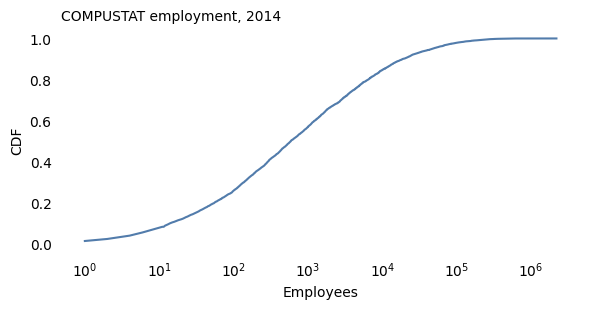

In [11]:
Cdf.from_seq(employees).plot()

decorate(xlabel="Employees", ylabel="CDF", xscale="log", title=f"COMPUSTAT employment, {year}")

The CDF on a log scale has the sigmoid shape characteristic of a normal distribution.
So the lognormal model seems promising.

In [12]:
tail = TailDist.from_seq(employees)

In [13]:
xlabel = "Employees"
ylabel = "Prob >= $x$"

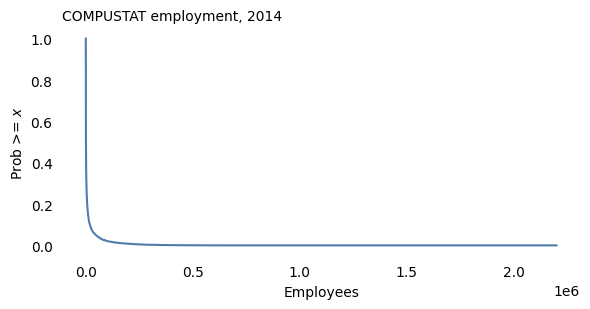

In [14]:
tail.plot()

decorate(xlabel=xlabel, ylabel=ylabel, title=f"COMPUSTAT employment, {year}")

On log-log axes, a Zipf distribution ($\alpha = 1$) would be a straight line with slope $-1$.


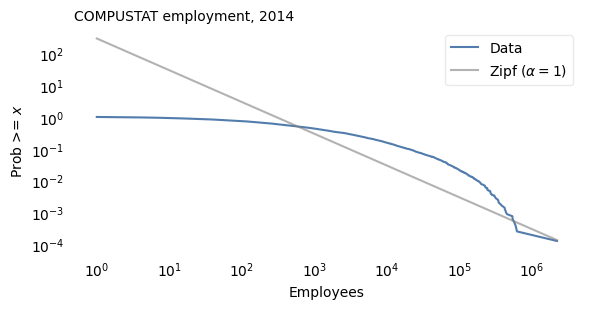

In [15]:
tail.plot(label="Data")

# Reference Zipf line anchored near the median of the sample
x0 = float(employees.median())
p0 = float(tail(x0))
xs = np.logspace(np.log10(employees.min()), np.log10(employees.max()), 200)
plt.plot(xs, p0 * (x0 / xs), color="gray", alpha=0.6, label=r"Zipf ($\alpha=1$)")

decorate(xlabel=xlabel, ylabel=ylabel, xscale="log", yscale="log",
         title=f"COMPUSTAT employment, {year}")
plt.legend();

## Log employment

Following the pattern used elsewhere in this book for heavy-tailed positive quantities, work with $\log_{10}$ employment.
A Gaussian fit on that scale is a lognormal model for employment.


In [16]:
mags = np.log10(employees)
mags.describe()

count    7974.000000
mean        2.762816
std         1.170211
min         0.000000
25%         1.977724
50%         2.770115
75%         3.621150
max         6.342423
Name: employees, dtype: float64

In [17]:
tail_log = TailDist.from_seq(mags)

In [18]:
xlabel_log = "Employees (log10)"

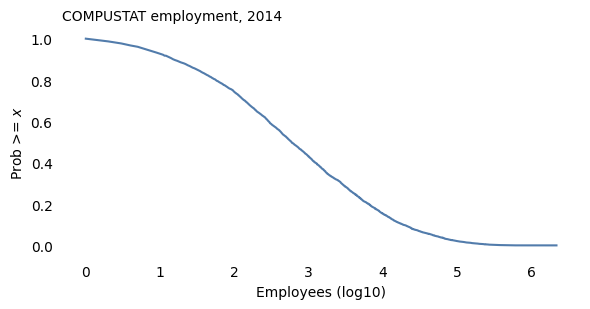

In [19]:
tail_log.plot()

decorate(xlabel=xlabel_log, ylabel=ylabel, title=f"COMPUSTAT employment, {year}")

## Fitting truncated models

COMPUSTAT is missing most small firms, so I'll treat the smallest value in the sample as a cutoff and truncate each model there.
I'll fit four models the same way as in [the French firm-size example](https://allendowney.github.io/ProbablyOverthinkingIt/firm_size_france.html), using functions in [`tail_models.py`](https://github.com/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/tail_models.py):

* Location and scale are chosen to match percentiles of the data (`fit_loc_scale`).
* A shape parameter, if the model has one, is chosen to match the largest values -- it minimizes the squared differences between the logarithms of the tail probabilities, from 1% down to the second-largest value (`fit_shape`).

For each model, `plot_two` shows the data and the model on a linear-$y$ scale and a log-$y$ scale, side by side; on the log-$y$ scale, the shaded area shows how much variation we would expect due to sampling if the model were correct.
And `model_errors` computes two kinds of error: the mean absolute difference between the tail distributions on the linear scale, which is mostly sensitive to discrepancies among most of the data, and the root mean squared difference between log tail probabilities, which is mostly sensitive to discrepancies among the largest firms.

In [20]:
from tail_models import (
    truncated_tail,
    fit_loc_scale,
    fit_shape,
    pareto2_tail,
    fit_pareto2_scale,
    fit_pareto2_alpha,
    plot_two,
    model_errors,
    fit_models,
    YTICKS_LOG,
)

I'll evaluate all models on the same grid, extending a little beyond the largest value.

In [21]:
low, high = tail_log.qs.min(), tail_log.qs.max()
qs = np.linspace(low, high + 0.5, 2000)
log_cutoff = low

In [22]:
results = {}

## Lognormal model

For the lognormal model, I fit a normal distribution to log employment, truncated at the cutoff, matching percentiles from the 10th to the 99th.

In [23]:
from scipy.stats import norm

mu, sigma = fit_loc_scale(norm, tail_log, ps=np.linspace(0.1, 0.99, 20))
mu, sigma

(2.7526170525860327, 1.2434875604466937)

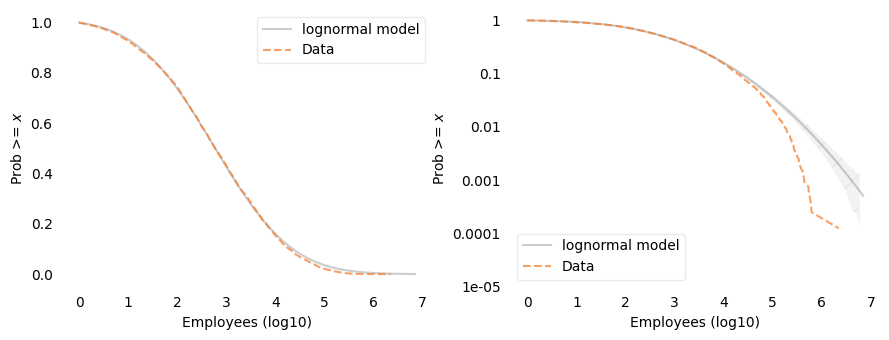

In [24]:
tail_lognormal = truncated_tail(norm, qs, mu, sigma)
plot_two(tail_log, tail_lognormal, n, "lognormal model", xlabel_log)

On the linear-$y$ scale, the lognormal model fits the data well.
On the log-$y$ scale, we can see that it doesn't: above about 30,000 employees, the data fall below the model, and for the largest firms the discrepancy is more than an order of magnitude -- well outside the range we would expect from random sampling.
So the largest firms are *less* common than the lognormal model predicts, consistent with Stanley et al.

In [25]:
results["lognormal"] = model_errors(tail_log, tail_lognormal)
results["lognormal"]

(0.004420969591287691, 0.6195509024771162)

## Log-Student-$t$ model

The Student-$t$ distribution has a parameter, `df`, that controls the thickness of the tails.
With large values of `df`, it is nearly normal; with small values, it has much thicker tails.
So a log-Student-$t$ model can only have thicker tails than the lognormal model.

In [26]:
from scipy.stats import t as t_dist

df_t = fit_shape(t_dist, tail_log, shape0=10, bounds=(1, 1000))
df_t

999.9997120471248

In [27]:
mu_t, sigma_t = fit_loc_scale(t_dist, tail_log, shape=(df_t,))
mu_t, sigma_t

(2.752286387100959, 1.242587556285159)

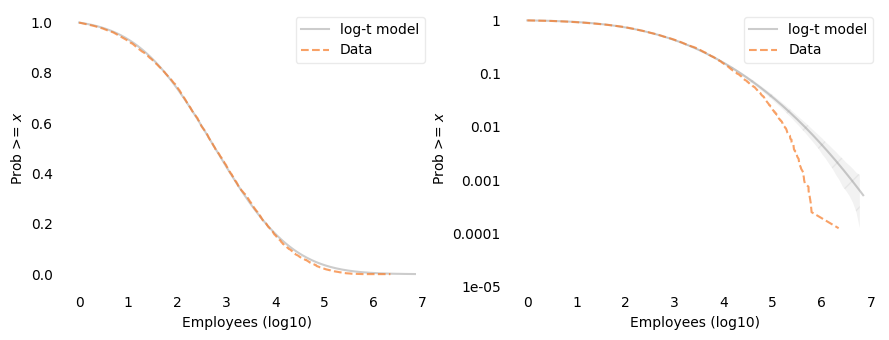

In [28]:
tail_t = truncated_tail(t_dist, qs, df_t, mu_t, sigma_t)
plot_two(tail_log, tail_t, n, "log-t model", xlabel_log)

The fitted value of `df` is at the upper bound of the search, 1000, so the best log-$t$ model is indistinguishable from the lognormal model.
That's what we should expect: the Student-$t$ distribution can make the tails thicker, but these data need thinner tails.

In [29]:
results["log-t"] = model_errors(tail_log, tail_t)
results["log-t"]

(0.004444207486111745, 0.6208268143621467)

## Log-generalized-normal model

The generalized normal (exponential-power) distribution has a shape parameter, $\beta$, that can make the tails thicker or thinner than normal: $\beta = 2$ is the normal distribution, $\beta < 2$ has thicker tails, and $\beta > 2$ has thinner tails.
So the lognormal model is a special case, and the fitted value of $\beta$ shows which way the data depart from it, if they do.

In [30]:
from scipy.stats import gennorm

beta = fit_shape(gennorm, tail_log, shape0=2, bounds=(0.5, 20))
beta

3.1702926757786543

In [31]:
mu_g, alpha_g = fit_loc_scale(gennorm, tail_log, shape=(beta,))
mu_g, alpha_g

(2.773603953301865, 1.8560689554953045)

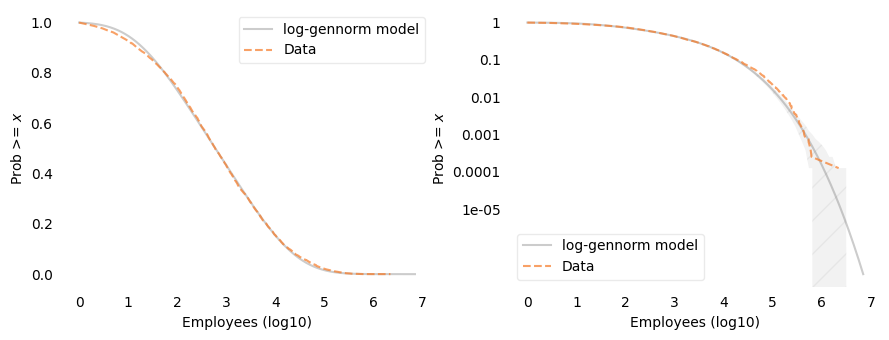

In [32]:
tail_gennorm = truncated_tail(gennorm, qs, beta, mu_g, alpha_g)
plot_two(tail_log, tail_gennorm, n, "log-gennorm model", xlabel_log)

The fitted value of $\beta$ is about 3.2, greater than 2, so the departure from the lognormal model is toward thinner tails.
The log-generalized-normal model fits well on both scales.
On the log-$y$ scale, the data are mostly within the range we would expect from random sampling; the few largest firms are above the model, near the edge of that range.

In [33]:
results["log-gennorm"] = model_errors(tail_log, tail_gennorm)
results["log-gennorm"]

(0.0063481086616869135, 0.1131234415369943)

## Pareto model

A Pareto distribution has a tail distribution $P(X \ge x) = (x / x_m)^{-\alpha}$, which is a straight line with slope $-\alpha$ on log-log axes; with $\alpha = 1$, it is a Zipf distribution.
Truncated at the cutoff, it has only one parameter, so I'll use the more flexible Pareto II (Lomax) distribution, which has a scale parameter, $s$, as well as the exponent:

$$P(X \ge x ~|~ X \ge c) = \left(1 + \frac{x - c}{s}\right)^{-\alpha}$$

where $c$ is the cutoff.
For values much larger than $c + s$, it behaves like a Pareto distribution with exponent $\alpha$; near the cutoff, the scale parameter controls how it bends.
As with the other models, `fit_pareto2_alpha` chooses $\alpha$ to match the largest values, and `fit_pareto2_scale` chooses the scale to match percentiles.

In [34]:
alpha = fit_pareto2_alpha(tail_log, log_cutoff)
alpha

0.9145875096543682

In [35]:
log_scale = fit_pareto2_scale(tail_log, alpha, log_cutoff)
log_scale, 10**log_scale

(2.7151528259576967, 518.9826340756359)

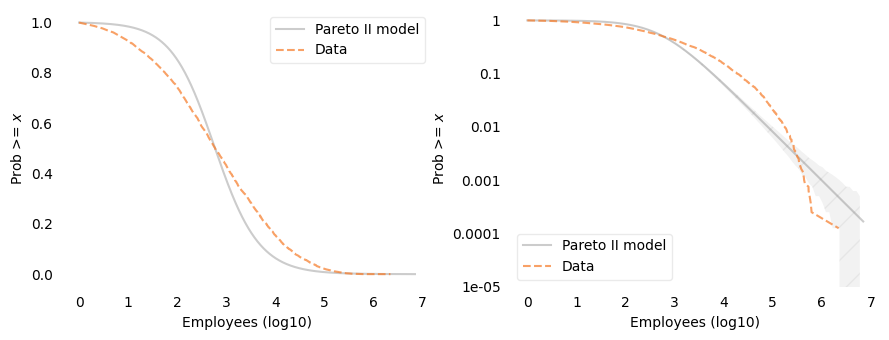

In [36]:
tail_pareto = pareto2_tail(qs, alpha, log_scale, log_cutoff)
plot_two(tail_log, tail_pareto, n, "Pareto II model", xlabel_log)

The fitted exponent is about 0.91, and the scale is about 500 employees.
The Pareto II model does not fit this distribution: on the linear-$y$ scale, it is visibly off over most of the range, and on the log-$y$ scale it is below the data between about 1,000 and 300,000 employees and above the data for the largest firms.

In [37]:
results["Pareto II"] = model_errors(tail_log, tail_pareto)
results["Pareto II"]

(0.07508412599596526, 0.3622964560323112)

## Comparison

Here are all four models on a log-$y$ scale.

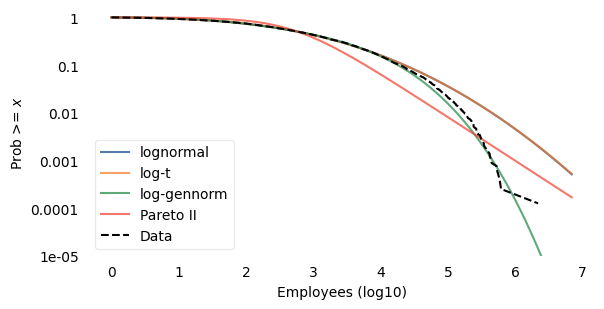

In [38]:
tail_lognormal.plot(label="lognormal")
tail_t.plot(label="log-t")
tail_gennorm.plot(label="log-gennorm")
tail_pareto.plot(label="Pareto II")
tail_log.plot(color="black", ls="--", label="Data")

decorate(xlabel=xlabel_log, ylabel=ylabel, yscale="log", ylim=[1e-5, 1.5])
plt.yticks(YTICKS_LOG, YTICKS_LOG);

And here are the errors.

In [39]:
pd.DataFrame(results, index=["Mean abs error", "RMS log error"]).T.round(4)

,Mean abs error,RMS log error
lognormal,0.0044,0.6196
log-t,0.0044,0.6208
log-gennorm,0.0063,0.1131
Pareto II,0.0751,0.3623


The lognormal and log-$t$ curves are the same, so only one is visible.
The log-generalized-normal model has the smallest error on the log scale by a wide margin; the lognormal model has a slightly smaller error on the linear scale; and the Pareto II model has the largest error on the linear scale.

## Robustness

To see whether these results depend on the year or the cutoff, I'll fit the lognormal, log-generalized-normal, and Pareto II models for each fiscal year from 2005 through 2014, and for several cutoffs.
The following function selects the data.

In [40]:
def select_employment(raw, year, cutoff):
    """Select log employment at or above the cutoff for one fiscal year."""
    employees = raw.loc[raw["fyear"] == year, "emp"] * 1000
    return np.log10(employees[employees >= cutoff])

`fit_models`, in `tail_models.py`, fits the lognormal, log-generalized-normal, and Pareto II models to one dataset and returns the parameters and errors.
With no cutoff argument, it uses the smallest value, as above.

Here are the results for each year, using all firms with positive employment.

In [41]:
min_employees = employees.min()
rows = {y: fit_models(select_employment(raw, y, min_employees)) for y in range(2005, 2015)}
by_year = pd.DataFrame(rows).T
by_year.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
2005,9299.0,2.527,0.933,2.655,0.398,0.117,0.332
2006,9133.0,2.509,0.925,2.650,0.396,0.122,0.333
2007,8893.0,2.536,0.916,2.646,0.404,0.138,0.343
2008,8508.0,2.573,0.922,2.685,0.417,0.145,0.342
2009,8291.0,2.575,0.929,2.701,0.424,0.154,0.345
2010,8211.0,2.724,0.927,2.707,0.482,0.145,0.350
2011,8118.0,2.799,0.919,2.705,0.511,0.142,0.355
2012,8107.0,3.004,0.909,2.684,0.575,0.125,0.361
2013,8182.0,3.117,0.906,2.675,0.603,0.121,0.365
2014,7974.0,3.170,0.915,2.715,0.620,0.113,0.362


In every year from 2005 through 2014, the log-generalized-normal model fits best on the log scale, with $\beta$ between 2.5 and 3.2 -- always thinner-tailed than the lognormal model.
The fitted value of $\beta$ increases over the decade.
The lognormal and Pareto II models fit substantially worse in every year, and the Pareto exponent is between 0.91 and 0.93.

And here are the results for fiscal year 2014 with several cutoffs.

In [42]:
cutoffs = [10, 100, 1000, 10_000]
rows = {f"{c:,}": fit_models(select_employment(raw, year, c), np.log10(c)) for c in cutoffs}
by_cutoff = pd.DataFrame(rows).T
by_cutoff.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
10,7393.0,2.995,0.960,2.862,0.602,0.121,0.349
100,5928.0,5.443,1.078,3.208,0.603,0.091,0.312
"1,000",3444.0,20.000,1.383,3.854,0.456,0.132,0.236
"10,000",1236.0,19.984,2.110,4.654,0.443,0.394,0.146


The results depend on the cutoff.
As the cutoff increases, $\beta$ increases, from about 3 with a cutoff of 10 employees to about 5.4 with a cutoff of 100.
With cutoffs of 1,000 and 10,000 employees, $\beta$ reaches the upper bound of the search, 20, where the generalized normal is nearly uniform, so those fits are not meaningful; with the 10,000 cutoff, the log-generalized-normal error is large.

The Pareto II model goes the other way: as the cutoff increases, the exponent increases, from about 0.96 to about 2.1, and the fit gets better.
With the 10,000 cutoff, it fits better than the other models, with exponent about 2 -- a much steeper tail than a Zipf distribution.

So among the roughly 1,200 firms with 10,000 or more employees, the distribution of employment is consistent with a Pareto II distribution with exponent about 2; over the whole sample, a log-generalized-normal distribution with thinner tails than the lognormal fits best.

## Summary

1. Progress is slow for mutually reinforcing reasons: proprietary data, top-coded public tables, plots poorly suited to seeing the tail, and no shared definition of “best fit” when every candidate is an acknowledged approximation.
2. COMPUSTAT is the wrong sample for the whole firm population and the right one for inspecting individual upper-tail sizes.
3. In this 2014 extract, a lognormal describes most of log employment well; the extreme CCDF falls *below* that prediction — a lighter-than-lognormal tail. A log-Student-$t$ model can't help, because it can only make the tails thicker.
4. A generalized normal on $\log_{10}$ employment diagnoses the direction of failure ($\beta \approx 3.2$ here, greater than 2) rather than declaring a new favorite family in advance. It fits best in every year from 2005 through 2014.
5. A Pareto II model does not fit the whole sample, but among firms with 10,000 or more employees it fits better than the others, with exponent about 2.

Copyright 2026 Allen B. Downey

Example related to Chapters 4 and 8 from [Probably Overthinking It](https://allendowney.github.io/ProbablyOverthinkingIt/).

License: [Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/)